# YouTube Live Chat Data Audit

Notebook này kiểm tra cấu trúc và phân phối dữ liệu `youtube_live_chat.jsonl` để hỗ trợ kiểm thử pipeline Spark/Kafka. Phân tích ngôn ngữ chỉ là heuristic; đây không phải đánh giá mô hình sentiment.

## IMPORT MODULE + SET UP

In [1]:
# 1. Setup
from collections import Counter
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in candidates if (path / "data" / "raw" / "youtube_live_chat.jsonl").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Không tìm thấy data/raw/youtube_live_chat.jsonl. "
        "Hãy chạy notebook từ bên trong folder YTB_LIVE_SENTIMENT."
    )

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "youtube_live_chat.jsonl"
print(f"Project root: {PROJECT_ROOT}")
print(f"Input file: {DATA_PATH}")

Project root: d:\TEIKYUD\YTB_LIVE_SENTIMENT
Input file: d:\TEIKYUD\YTB_LIVE_SENTIMENT\data\raw\youtube_live_chat.jsonl


## LOADING DATA

In [ ]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(DATA_PATH)

df = pd.read_json(DATA_PATH, lines=True, convert_dates=False, dtype={"schema_version": str})
print(f"Loaded {len(df):,} records")
display(df.head())

Loaded 20,563 records


,message_id,video_id,timestamp,collected_at,author,text,message_type,source,schema_version
0,ChwKGkNKcVRudFRGejVjREZXVEh3Z1FkZXVVVXBn,V13LZc75GUo,2026-10-23 13:47:28,2026-10-24T13:20:21.857828+00:00,@HoaPham-m9h5z,Mùa này thua FPL chắc 100%,textMessage,youtube_live,1.0
1,ChwKGkNNR1AtdGZGejVjREZYUFB3Z1FkR3FROFZn,V13LZc75GUo,2026-10-23 13:47:35,2026-10-24T13:20:25.713082+00:00,@GybFbbnhsef,đương kim á quân xin được gọi tên FPT poly,textMessage,youtube_live,1.0
2,ChwKGkNQVHR5dHJGejVjREZadmV3Z1FkWDNjTC1R,V13LZc75GUo,2026-10-23 13:47:41,2026-10-24T13:20:29.568594+00:00,@nguyenphamvan9840,Nhà vua vẫn là nhà vua,textMessage,youtube_live,1.0
3,ChwKGkNJenI1TnZGejVjREZYM0Y1d01kLXdRSm93,V13LZc75GUo,2026-10-23 13:47:43,2026-10-24T13:20:33.424134+00:00,@09.trantruonghuynhhan60,sao chưa vào nhỉ,textMessage,youtube_live,1.0
4,ChwKGkNMNjkwdF9GejVjREZROVVUQWdkXzhJQUhn,V13LZc75GUo,2026-10-23 13:47:51,2026-10-24T13:20:37.279260+00:00,@QuangTranNgocMinh,mang fpt polytechnic,textMessage,youtube_live,1.0


## BASIC OVERVIEW

In [ ]:
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Unique videos: {df['video_id'].nunique(dropna=True) if 'video_id' in df else 'field missing'}")
print(f"Unique authors: {df['author'].nunique(dropna=True) if 'author' in df else 'field missing'}")
print(f"Unique message IDs: {df['message_id'].nunique(dropna=True) if 'message_id' in df else 'field missing'}")
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "non_null": df.notna().sum()}))

Shape: 20,563 rows x 9 columns
Unique videos: 1
Unique authors: 5733
Unique message IDs: 20563


,dtype,non_null
message_id,object,20563
video_id,object,20563
timestamp,object,20563
collected_at,object,20563
author,object,20563
text,object,20563
message_type,object,20563
source,object,20563
schema_version,object,20563


## MISSING & EMPTY VALUE

,missing_values,missing_pct
message_id,0,0.0
video_id,0,0.0
timestamp,0,0.0
collected_at,0,0.0
author,0,0.0
text,0,0.0
message_type,0,0.0
source,0,0.0
schema_version,0,0.0


Empty/whitespace text: 11 (0.05%)


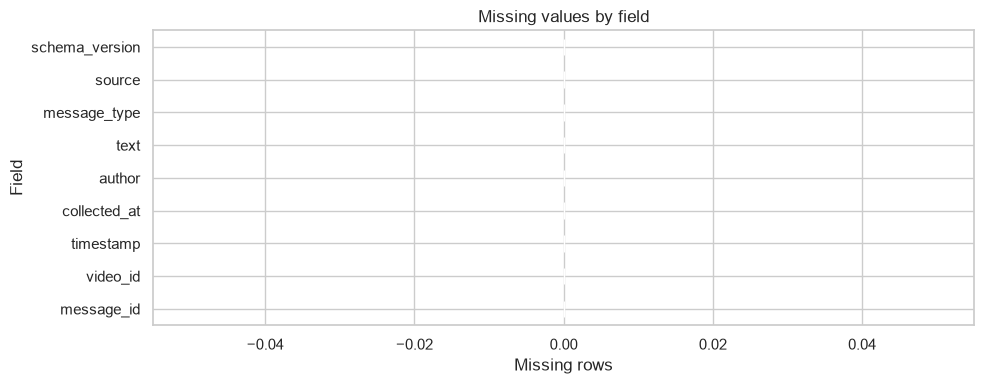

In [ ]:
missing_summary = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
}).sort_values("missing_values", ascending=False)

display(missing_summary)

if "text" in df.columns:
    text_values = df["text"].fillna("").astype(str)
    empty_text = text_values.str.strip().eq("")
    print(f"Empty/whitespace text: {empty_text.sum():,} ({empty_text.mean() * 100:.2f}%)")

fig, ax = plt.subplots(figsize=(10, 4))
missing_summary["missing_values"].sort_values().plot.barh(ax=ax, color="#d97757")
ax.set(title="Missing values by field", xlabel="Missing rows", ylabel="Field")
plt.tight_layout()
plt.show()

## DUPLICATE ANALYSIS

In [ ]:
if "message_id" in df.columns:
    duplicate_id_rows = int(df["message_id"].duplicated(keep="first").sum())
    print(f"Duplicate message_id rows: {duplicate_id_rows:,}")

if "text" in df.columns:
    normalized_text = df["text"].fillna("").astype(str).str.strip().str.casefold()
    duplicate_text_rows = int(normalized_text.duplicated(keep="first").sum())
    print(f"Repeated text rows after first occurrence: {duplicate_text_rows:,} ({duplicate_text_rows / max(len(df), 1) * 100:.2f}%)")
    top_repeated_text = normalized_text.value_counts().loc[lambda values: values > 1].head(15)
    display(top_repeated_text.rename("count").to_frame())

Duplicate message_id rows: 0
Repeated text rows after first occurrence: 7,081 (34.44%)


,count
text,
ngulius,191
hay,159
anh dễ,103
4-1,92
mã 38 vé chung sức nhập nhanh ko hết --pf75yibf3s--,90
fpl,87
mã 38 vé chung sức đây mn nhập nhanh kẻo hết --pf75yibf3s--,86
mã 38 vé chung sức đây mn nhập nhanh kẻo hết 8avqmexpqd,82
mã 38 vé đây nha ae: l8djg9j8gu,78


## EMOJI ANALYSIS

Messages containing emoji/token: 1,006 (4.89%)


,emoji_or_token,count
0,:face-blue-smiling:,897
1,:face-purple-crying:,374
2,:body-green-covering-eyes:,194
3,:face-green-smiling:,130
4,:rolling_on_the_floor_laughing:,127
5,:hand-pink-waving:,109
6,:face-red-heart-shape:,107
7,:face-orange-biting-nails:,67
8,:face_savoring_food:,65
9,:cat-orange-whistling:,52


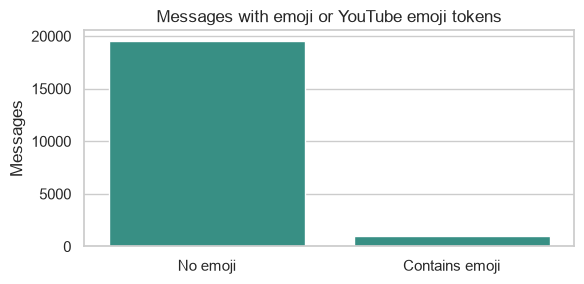

In [15]:
emoji_pattern = re.compile(r":[A-Za-z0-9_-]+:|[\U0001F300-\U0001FAFF\U00002600-\U000027BF]")
text_values = df["text"].fillna("").astype(str) if "text" in df.columns else pd.Series(dtype=str)
emoji_tokens = text_values.map(emoji_pattern.findall)
contains_emoji = emoji_tokens.map(bool)

print(f"Messages containing emoji/token: {contains_emoji.sum():,} ({contains_emoji.mean() * 100 if len(contains_emoji) else 0:.2f}%)")
top_emoji_tokens = Counter(token for tokens in emoji_tokens for token in tokens).most_common(15)
display(pd.DataFrame(top_emoji_tokens, columns=["emoji_or_token", "count"]))

if len(contains_emoji):
    fig, ax = plt.subplots(figsize=(6, 3))
    sns.countplot(x=contains_emoji.map({True: "Contains emoji", False: "No emoji"}), ax=ax, color="#2a9d8f")
    ax.set(title="Messages with emoji or YouTube emoji tokens", xlabel="", ylabel="Messages")
    plt.tight_layout()
    plt.show()

## LANGUAGE ANALYSIS

,category,messages
0,Vietnamese diacritics,14818
1,ASCII / undetermined,5443
2,Other Unicode / undetermined,291
3,Empty,11


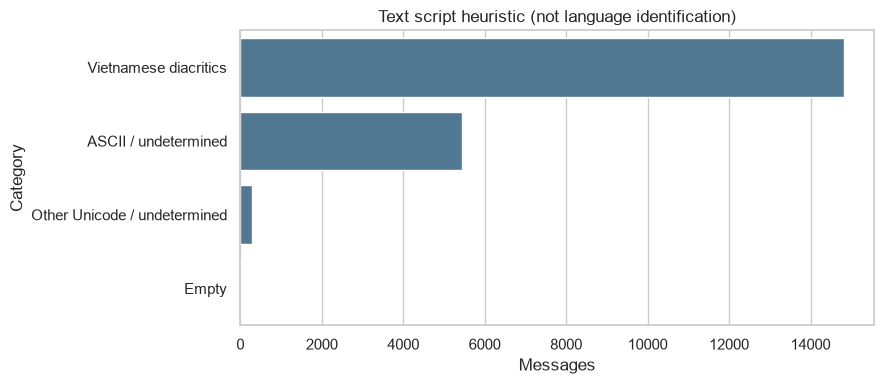

In [8]:
# 7. Language Analysis (heuristic)
# Detect Vietnamese-specific letters/diacritics; this does not reliably identify language.
vietnamese_pattern = re.compile(r"[ăâđêôơưĂÂĐÊÔƠƯáàảãạấầẩẫậắằẳẵặéèẻẽẹếềểễệíìỉĩịóòỏõọốồổỗộớờởỡợúùủũụứừửữựýỳỷỹỵ]", re.IGNORECASE)
non_ascii_pattern = re.compile(r"[^\x00-\x7F]")
text_values = df["text"].fillna("").astype(str) if "text" in df.columns else pd.Series(dtype=str)

has_vietnamese_marks = text_values.map(lambda value: bool(vietnamese_pattern.search(value)))
has_other_unicode = text_values.map(lambda value: bool(non_ascii_pattern.search(value)))
empty_text = text_values.str.strip().eq("")

df["language_heuristic"] = np.select(
    [empty_text, has_vietnamese_marks, has_other_unicode],
    ["Empty", "Vietnamese diacritics", "Other Unicode / undetermined"],
    default="ASCII / undetermined",
)
language_counts = df["language_heuristic"].value_counts().rename_axis("category").reset_index(name="messages")
display(language_counts)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=language_counts, x="messages", y="category", ax=ax, color="#457b9d")
ax.set(title="Text script heuristic (not language identification)", xlabel="Messages", ylabel="Category")
plt.tight_layout()
plt.show()

## MESSAGE LENGTH

,count,mean,std,min,50%,95%,max
message_length_chars,20563.0,23.010018,24.630087,1.0,16.0,62.0,376.0
message_length_words,20563.0,4.733696,3.950610,0.0,4.0,12.0,46.0


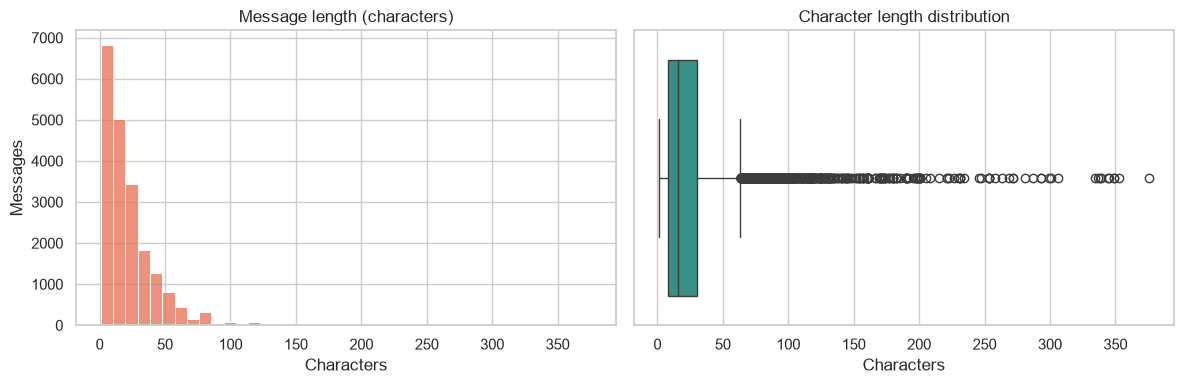

In [ ]:
text_values = df["text"].fillna("").astype(str) if "text" in df.columns else pd.Series(dtype=str)
df["message_length_chars"] = text_values.str.len()
df["message_length_words"] = text_values.str.split().str.len()

length_summary = df[["message_length_chars", "message_length_words"]].describe(percentiles=[0.5, 0.95]).T
display(length_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["message_length_chars"], bins=40, ax=axes[0], color="#e76f51")
axes[0].set(title="Message length (characters)", xlabel="Characters", ylabel="Messages")
sns.boxplot(x=df["message_length_chars"], ax=axes[1], color="#2a9d8f")
axes[1].set(title="Character length distribution", xlabel="Characters")
plt.tight_layout()
plt.show()

## TIMESTAMP ANALYSIS

,count,mean,std,min,50%,95%,max
collection_lag_minutes,20563.0,1412.836898,0.092979,1411.625724,1412.843134,1412.958049,1413.309336


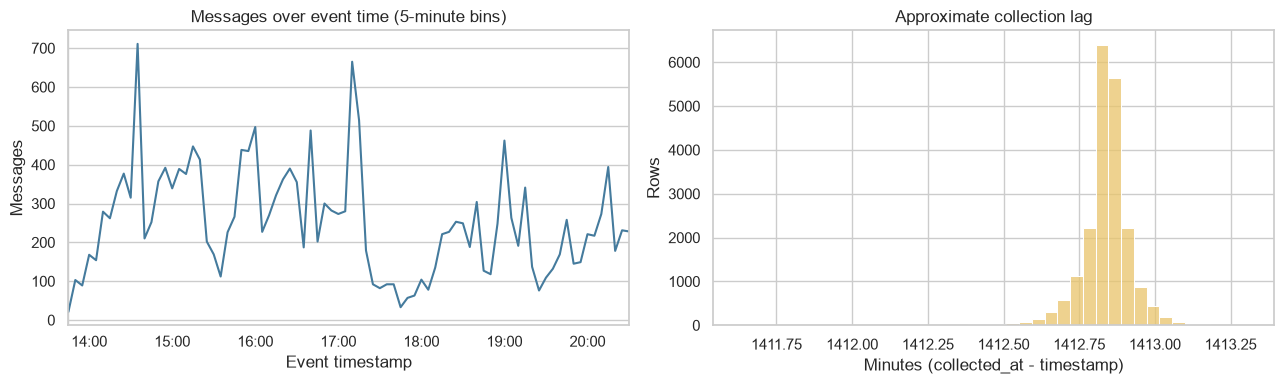

Lưu ý: timestamp không có timezone; độ trễ chỉ mang tính xấp xỉ khi so với collected_at UTC.


In [ ]:
if {"timestamp", "collected_at"}.issubset(df.columns):
    event_time = pd.to_datetime(df["timestamp"], errors="coerce")
    collected_time = pd.to_datetime(df["collected_at"], errors="coerce", utc=True).dt.tz_localize(None)
    df["event_time_parsed"] = event_time
    df["collection_lag_minutes"] = (collected_time - event_time).dt.total_seconds() / 60

    valid_event_time = df.dropna(subset=["event_time_parsed"]).set_index("event_time_parsed")
    messages_per_5min = valid_event_time.resample("5min").size()
    display(df[["collection_lag_minutes"]].describe(percentiles=[0.5, 0.95]).T)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    messages_per_5min.plot(ax=axes[0], color="#457b9d")
    axes[0].set(title="Messages over event time (5-minute bins)", xlabel="Event timestamp", ylabel="Messages")
    sns.histplot(df["collection_lag_minutes"].dropna(), bins=40, ax=axes[1], color="#e9c46a")
    axes[1].set(title="Approximate collection lag", xlabel="Minutes (collected_at - timestamp)", ylabel="Rows")
    plt.tight_layout()
    plt.show()
    print("Lưu ý: timestamp không có timezone; độ trễ chỉ mang tính xấp xỉ khi so với collected_at UTC.")
else:
    print("Missing timestamp or collected_at; timestamp analysis skipped.")

## SCHEMA VALIDATION

In [ ]:
import json

with DATA_PATH.open(encoding="utf-8") as input_file:
    source_columns = list(json.loads(input_file.readline()).keys())

required_types = {
    "message_id": str,
    "video_id": str,
    "timestamp": str,
    "collected_at": str,
    "author": str,
    "text": str,
    "message_type": str,
    "source": str,
    "schema_version": str,
}

schema_errors = []
for field, expected_type in required_types.items():
    if field not in source_columns:
        schema_errors.append({"field": field, "issue": "missing required field", "rows": len(df)})
        continue
    invalid_type = df[field].notna() & ~df[field].map(lambda value: isinstance(value, expected_type))
    if invalid_type.any():
        schema_errors.append({"field": field, "issue": f"expected {expected_type.__name__}", "rows": int(invalid_type.sum())})

schema_errors_df = pd.DataFrame(schema_errors, columns=["field", "issue", "rows"])
if schema_errors_df.empty:
    print("Schema validation passed: all required fields and non-null values have expected types.")
else:
    display(schema_errors_df)

extra_fields = sorted(set(source_columns) - set(required_types))
print("Observed source schema:", sorted(source_columns))
print("Unexpected source fields:", extra_fields)
print("Schema versions:", sorted(df["schema_version"].dropna().astype(str).unique()) if "schema_version" in df else "field missing")

Schema validation passed: all required fields and non-null values have expected types.
Observed source schema: ['author', 'collected_at', 'message_id', 'message_type', 'schema_version', 'source', 'text', 'timestamp', 'video_id']
Unexpected source fields: []
Schema versions: ['1.0']


## CONCLUSION

In [ ]:
benchmark_summary = {
    "records": len(df),
    "source_columns": len(source_columns),
    "videos": df["video_id"].nunique(dropna=True) if "video_id" in df else np.nan,
    "unique_message_ids": df["message_id"].nunique(dropna=True) if "message_id" in df else np.nan,
    "empty_text_rows": int(df["text"].fillna("").astype(str).str.strip().eq("").sum()) if "text" in df else np.nan,
    "repeated_text_rows": int(df["text"].fillna("").astype(str).str.strip().str.casefold().duplicated().sum()) if "text" in df else np.nan,
    "schema_errors": len(schema_errors_df),
}
display(pd.Series(benchmark_summary, name="value").to_frame())

print(
    "Benchmark notes: this dataset is suitable for functional and small-scale pipeline tests. "
    "For throughput/scalability tests, replay at controlled rates, track consumer lag and end-to-end latency, "
    "and scale volume while preserving the intended Kafka partition-key distribution. "
    "Repeated messages are valid input for throughput tests; use unique generated IDs when replaying "
    "if message_id deduplication is part of the measured workload."
)

,value
records,20563
source_columns,9
videos,1
unique_message_ids,20563
empty_text_rows,11
repeated_text_rows,7081
schema_errors,0


Benchmark notes: this dataset is suitable for functional and small-scale pipeline tests. For throughput/scalability tests, replay at controlled rates, track consumer lag and end-to-end latency, and scale volume while preserving the intended Kafka partition-key distribution. Repeated messages are valid input for throughput tests; use unique generated IDs when replaying if message_id deduplication is part of the measured workload.
